# 4.3 — NumPy/SciPy and JAX

Run all cells to download the verified public dataset and redraw the two
French-labelled thesis figures. This notebook needs only NumPy and Matplotlib,
available in Google Colab. It needs no repository installation, JAX, rclone,
credentials or new trajectory integration.

To run a new benchmark with your own Modal account, open the paired
[calculation notebook](https://colab.research.google.com/drive/1X-iiPUOFq35JgXlZF9XhMJQwZ-8DOBQ4).
Its results are separate from the archived measurements displayed here.

The original experiment compares BM4 with symmetric projection, two-stage
Gauss–Legendre and explicit midpoint RK2 over 10, 30 and 90 cycles. Each case
uses the same 16 initial particles, normalized gyro-radius 0.015, 40 fixed
steps per cycle and ten saved samples per cycle. Both libraries execute
successively in one two-core Modal CPU worker per case, with float64 states.
Each library has one first invocation and three subsequent invocations; their
order alternates. These are the **original recorded timings**, not measurements
on the current Colab runtime. Timing excludes input restoration, transfers and
plots; it includes preparation, integration, synchronization and host results.

The public bundle contains all saved paired trajectories and individual times.
Its pinned manifest verifies every downloaded file. The notebook recomputes
medians, ranges and Euclidean distances from those records. It checks the
original compilation-cache records but does not repeat the original
determinism test: trajectories from the later repetitions were not retained.

Agreement compares the same particle across libraries in unwrapped base-cell
coordinates; it is not accuracy relative to an exact solution. The two groups
contain eight chaotic candidates and eight periodic candidates. Their
classifications remain provisional.


In [1]:
from hashlib import sha256
import io
import json
from pathlib import Path
from typing import Any
from urllib.error import HTTPError, URLError
from urllib.parse import urlsplit
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np

PUBLIC_DATA_BASE_URL = "https://f003.backblazeb2.com/file/gc2d-colab-public/04_03_numpy_jax/methods-20261119-union16-rho0015-c10-30-90/v1"
EXPECTED_MANIFEST_SHA256 = "327a81f8566269eee2976322ec6083fe584c4d7e001b9401a8768f23547de398"
STUDY_PREFIX = "studies/bm4_numpy_jax"
RUN_ID = "methods-20261119-union16-rho0015-c10-30-90"
METHODS = ("BM4Implicit", "GaussLegendre4", "RK2")
CYCLES = (10, 30, 90)
GROUP_IDS = {"chaotic": [12, 15, 18, 21, 24, 27, 30, 33],
    "periodic": [1, 2, 60, 64, 65, 72, 76, 83]}


def download_bytes(filename):
    """Read one bounded public object over HTTPS without credentials."""
    if urlsplit(PUBLIC_DATA_BASE_URL).scheme != "https":
        raise ValueError("The public data URL must use HTTPS.")
    request = Request(PUBLIC_DATA_BASE_URL.rstrip("/") + "/" + filename,
        headers={"User-Agent": "GC2D-Colab-visualisation/1"})
    try:
        with urlopen(request, timeout=60) as response:
            if urlsplit(response.url).scheme != "https":
                raise ValueError("The download was redirected away from HTTPS.")
            data = response.read(4 * 1024 * 1024 + 1)
    except (HTTPError, URLError, TimeoutError) as error:
        raise RuntimeError(f"Could not download {filename}. Check the runtime connection and retry this cell.") from error
    if not data or len(data) > 4 * 1024 * 1024:
        raise ValueError(f"Empty or unexpectedly large public object: {filename}.")
    return data


def load_public_data():
    """Verify the manifest pin and every object before interpreting arrays."""
    raw = download_bytes("manifest.json")
    if sha256(raw).hexdigest() != EXPECTED_MANIFEST_SHA256:
        raise ValueError("The public manifest differs from this notebook's pinned version.")
    manifest = json.loads(raw)
    if (manifest.get("schema_version") != 1 or manifest.get("study_prefix") != STUDY_PREFIX
            or manifest.get("run_id") != RUN_ID
            or set(manifest.get("files", {})) != {"study.json", "timings.json", "particles.json", "trajectories.npz"}):
        raise ValueError("The manifest describes an incompatible dataset.")
    contents = {}
    for name, expected in manifest["files"].items():
        data = download_bytes(name)
        if len(data) != expected["bytes"] or sha256(data).hexdigest() != expected["sha256"]:
            raise ValueError(f"Size or SHA-256 mismatch: {name}.")
        contents[name] = data
    with np.load(io.BytesIO(contents["trajectories.npz"]), allow_pickle=False) as saved:
        trajectories = {name: saved[name].copy() for name in saved.files}
    return (json.loads(contents["study.json"]), json.loads(contents["timings.json"]),
        json.loads(contents["particles.json"]), trajectories, manifest)


def summarize_saved(study, timings, particles, trajectories):
    """Check all 72 timing records and recompute distances from 18 trajectories."""
    protocol = dict(schema_version=2, study_prefix=STUDY_PREFIX, run_id=RUN_ID,
        methods=list(METHODS), cycles=list(CYCLES), repetitions=3, particle_count=16,
        rho=.015, reference_campaign="main-20261117-rho-div20",
        record_step_statistics=False, observers=False, progress=False)
    for key, expected in protocol.items():
        if study.get(key) != expected:
            raise ValueError(f"Unexpected study field: {key}.")
    ids = study["particle_ids"]
    if ids != sorted(GROUP_IDS["chaotic"] + GROUP_IDS["periodic"]) or set(particles) != set(GROUP_IDS):
        raise ValueError("Unexpected particle IDs or groups.")
    expected_cases = {f"{method}-{cycles}" for cycles in CYCLES for method in METHODS}
    expected_arrays = {f"{case}/{backend}/{name}" for case in expected_cases
        for backend in ("scipy", "jax") for name in ("t", "states")}
    if set(timings) != expected_cases or set(trajectories) != expected_arrays:
        raise ValueError("Missing, duplicated or unexpected cases or trajectory arrays.")
    groups = {}
    for group, data in particles.items():
        record = data["record"]
        requested = [p["id"] for p in record["particles"]]
        frozen = next(s for s in study["particle_selection"]["source_sets"] if s["source_file"] == data["source_file"])
        if requested != GROUP_IDS[group] or data["source_sha256"] != frozen["sha256"] or requested != frozen["particle_ids"]:
            raise ValueError("The group differs from its frozen particle selection.")
        groups[group] = dict(dataset_id=record["dataset_id"], requested_particle_ids=requested,
            available_particle_ids=requested, missing_particle_ids=[], source_file=data["source_file"],
            source_sha256=data["source_sha256"], status=record["status"],
            verified_for_reflected_potential=record["selection"]["verified_for_reflected_potential"])
    rows = []
    initial = None
    for cycles in CYCLES:
        for method in METHODS:
            case = f"{method}-{cycles}"
            pair = timings[case]["pair"]
            measurements = pair["measurements"]
            if len(measurements) != 8 or pair["environment"].get("x64") is not True or not timings[case].get("call_id"):
                raise ValueError("Incomplete paired measurements or float64 provenance.")
            expected_order = [(backend, repetition) for repetition in range(4)
                for backend in (("scipy", "jax") if repetition % 2 == 0 else ("jax", "scipy"))]
            if [(m["backend"], m["repetition"]) for m in measurements] != expected_order:
                raise ValueError("Incorrect alternating order or duplicated timing repetition.")
            for m in measurements:
                first = m["repetition"] == 0
                expected_cache = (int(first), int(not first)) if m["backend"] == "jax" else (0, 0)
                if (m["phase"] != ("first" if first else "warm")
                        or (m["integration_cache_misses"], m["integration_cache_hits"]) != expected_cache
                        or not np.isfinite([m["seconds"], m["process_seconds"]]).all()
                        or m["seconds"] <= 0 or m["process_seconds"] < 0):
                    raise ValueError("Invalid timing, phase or compilation-cache audit.")
            for backend in ("scipy", "jax"):
                t = trajectories[f"{case}/{backend}/t"]
                states = trajectories[f"{case}/{backend}/states"]
                if (states.dtype != np.float64 or states.shape != (10 * cycles + 1, 32)
                        or t.dtype != np.float64 or t.shape != (10 * cycles + 1,)
                        or not np.isfinite(states).all() or not np.isfinite(t).all()
                        or not np.allclose(t, np.linspace(0, cycles, 10 * cycles + 1), rtol=0, atol=1e-12)):
                    raise ValueError("Incomplete, nonfinite or misaligned trajectory.")
                if initial is None:
                    initial = states[0].copy()
                if not np.array_equal(initial, states[0]):
                    raise ValueError("The cases do not share identical initial states.")
            if not np.array_equal(trajectories[f"{case}/scipy/t"], trajectories[f"{case}/jax/t"]):
                raise ValueError("Paired sample times differ.")
            delta = trajectories[f"{case}/scipy/states"] - trajectories[f"{case}/jax/states"]
            distance = np.hypot(delta[:, :16], delta[:, 16:])
            metrics = dict(maximum_distance=float(distance.max()), rms_distance=float(np.sqrt(np.mean(distance**2))),
                final_maximum_distance=float(distance[-1].max()), maximum_distance_first_10_cycles=float(distance[:101].max()))
            if any(metrics[key] != pair["agreement"][key] for key in metrics):
                raise ValueError("The recomputed distances differ from the paired worker record.")
            row = dict(method=method, cycles=cycles, **metrics, environment=pair["environment"],
                call_id=timings[case]["call_id"], backends={}, group_distances={})
            for group, requested in GROUP_IDS.items():
                selected = distance[:, [ids.index(i) for i in requested]]
                row["group_distances"][group] = dict(maximum_distance=float(selected.max()),
                    per_particle_maximum_distance=selected.max(axis=0).tolist())
            for backend in ("scipy", "jax"):
                values = [m for m in measurements if m["backend"] == backend]
                warm = [m["seconds"] for m in values if m["phase"] == "warm"]
                row["backends"][backend] = dict(first_seconds=values[0]["seconds"], warm_seconds=warm,
                    median_seconds=float(np.median(warm)), minimum_seconds=min(warm), maximum_seconds=max(warm))
            row["speedup"] = row["backends"]["scipy"]["median_seconds"] / row["backends"]["jax"]["median_seconds"]
            rows.append(row)
    return dict(study=study, rows=rows, particle_groups=groups,
        agreement_convention="Unwrapped Euclidean distance in base-cell units; agreement is not accuracy.")


In [2]:
study, timings, particles, trajectories, public_manifest = load_public_data()
summary = summarize_saved(study, timings, particles, trajectories)
print(f"Verified dataset: {STUDY_PREFIX}/{RUN_ID}")
print("Verified 72 individual timings and 18 complete paired trajectories.")
print("Timing scope:", study["timing_scope"])
print("Recorded environment for each case:")
for case, record in timings.items():
    print(case, json.dumps(record["pair"]["environment"], sort_keys=True))
for row in summary["rows"]:
    print(f"{row['method']:14s} {row['cycles']:3d} cycles | speedup {row['speedup']:.2f} | "
        f"chaotic max {row['group_distances']['chaotic']['maximum_distance']:.3e} | "
        f"periodic max {row['group_distances']['periodic']['maximum_distance']:.3e}")


Verified dataset: studies/bm4_numpy_jax/methods-20261119-union16-rho0015-c10-30-90
Verified 72 individual timings and 18 complete paired trajectories.
Timing scope: Execution.run: preparation, integration, synchronization and result construction; excludes input decoding, files, network, audits and plots
Recorded environment for each case:
BM4Implicit-10 {"cpu_max": "unavailable", "cpu_model": "unknown", "jax": "0.7.1", "jaxlib": "0.7.1", "memory_max": "unavailable", "numpy": "1.26.4", "platform": "Linux-4.19.0-gvisor-x86_64-with-glibc2.36", "python": "3.12.10", "scipy": "1.17.1", "threads": {"MKL_NUM_THREADS": "2", "OMP_NUM_THREADS": "2", "OPENBLAS_NUM_THREADS": "2", "XLA_FLAGS": null}, "visible_logical_cpus": 2, "x64": true}
BM4Implicit-30 {"cpu_max": "unavailable", "cpu_model": "unknown", "jax": "0.7.1", "jaxlib": "0.7.1", "memory_max": "unavailable", "numpy": "1.26.4", "platform": "Linux-4.19.0-gvisor-x86_64-with-glibc2.36", "python": "3.12.10", "scipy": "1.17.1", "threads": {"MKL_N

## Runtime and particle separation

Runtime markers show the median of three later invocations, with minimum–maximum
bars. Hollow markers show the first invocation. Colors identify methods;
circles and solid lines identify NumPy/SciPy, squares and dashed lines JAX.
The ranges are not confidence intervals. No processor model was recorded;
equal resource requests do not prove identical hardware across distinct cases.

Each separation point is the maximum over all saved times and the eight
particles in its group, computed from the complete paired states. The two
panels share logarithmic scales. Connecting lines join independent runs of
different duration; they are not the time history of one trajectory. Values
equal to zero are never replaced by an artificial positive floor.


In [3]:
_METHOD_STYLES: dict[str, tuple[str, str]] = {
	'BM4Midpoint': ('BM4, moyenne', '#777777'),
	'BM4Implicit': ('BM4 implicite', '#9260a8'),
	'GaussLegendre4': ('Gauss–Legendre', '#d16b24'),
	'RK2': ('RK2', '#21856d'),
}

def plot_comparison(summary: dict[str, Any]) -> Any:
	"""Show all selected methods and both libraries on one logarithmic chart."""
	styles: dict[str, tuple[str, str]] = _METHOD_STYLES
	methods: list[str] = summary['study']['methods']
	cycles: list[int] = summary['study']['cycles']
	# Reject incomplete or nonpositive series before creating a log-scale figure.
	for method in methods:
		if method not in styles:
			raise ValueError(f'No plot style for method {method}.')
		selected: list[dict[str, Any]] = [r for r in summary['rows'] if r['method'] == method]
		if sorted(r['cycles'] for r in selected) != sorted(cycles):
			raise ValueError('The figure requires every selected duration exactly once.')
		for row in selected:
			for backend in ('scipy', 'jax'):
				v: dict[str, Any] = row['backends'][backend]
				if not (0 < v['minimum_seconds'] <= v['median_seconds'] <= v['maximum_seconds']
						and np.isfinite([v['minimum_seconds'], v['median_seconds'], v['maximum_seconds'], v['first_seconds']]).all()
						and v['first_seconds'] > 0):
					raise ValueError('Figure timings must be finite, positive and ordered.')
	fig: Any
	ax: Any
	fig, ax = plt.subplots(figsize=(7.6, 5.6), layout='constrained')
	for method in methods:
		label: str
		color: str
		label, color = styles[method]
		rows: list[dict[str, Any]] = sorted((row for row in summary['rows'] if row['method'] == method), key=lambda r: r['cycles'])
		x: np.ndarray = np.asarray([row['cycles'] for row in rows])
		for backend, linestyle, marker, name in (('scipy', '-', 'o', 'NumPy/SciPy'), ('jax', '--', 's', 'JAX')):
			values: list[dict[str, Any]] = [row['backends'][backend] for row in rows]
			median: np.ndarray = np.asarray([v['median_seconds'] for v in values])
			error: np.ndarray = np.asarray([[v['median_seconds']-v['minimum_seconds'] for v in values],
				[v['maximum_seconds']-v['median_seconds'] for v in values]])
			ax.errorbar(x, median, yerr=error, color=color, linestyle=linestyle, marker=marker,
				linewidth=1.6, markersize=5, capsize=4, label=f'{label} · {name}')
			ax.scatter(x, [v['first_seconds'] for v in values], marker=marker, s=52,
				facecolors='none', edgecolors=color, linewidths=1.1, zorder=4)
	ax.set(xscale='log', yscale='log', xlabel='Durée intégrée (cycles)', ylabel='Temps de calcul (s)')
	ax.set_xticks(cycles, [str(c) for c in cycles])
	ax.minorticks_off()
	ax.grid(True, which='major', alpha=.2)
	ax.spines[['top', 'right']].set_visible(False)
	handles: Any
	legend_labels: Any
	handles, legend_labels = ax.get_legend_handles_labels()
	legend_order: list[int] = list(range(0, len(handles), 2)) + list(range(1, len(handles), 2))
	fig.legend([handles[i] for i in legend_order], [legend_labels[i] for i in legend_order], loc='upper center',
		bbox_to_anchor=(.54, .935), ncol=2, fontsize=9, frameon=False)
	particle_count: int = summary['study'].get('particle_count', 40)
	fig.suptitle(str(particle_count) + r' particules · $\widetilde{\rho}=0{,}015$ · CPU (2 cœurs)', fontsize=11, y=.98)
	fig.get_layout_engine().set(rect=(0, .07, 1, .74))
	fig.text(.5, .018, 'Symboles pleins : médiane de 3 répétitions · Barres : min–max\nSymboles vides : premier appel',
		ha='center', fontsize=8.5)
	return fig

def plot_agreement(summary: dict[str, Any]) -> Any:
	"""Compare group maxima on common axes; absent groups retain the all-particle view."""
	methods: list[str] = summary['study']['methods']
	cycles: list[int] = summary['study']['cycles']
	groups: dict[str, dict[str, Any]] = summary.get('particle_groups', {})
	group_labels: dict[str, str] = {'chaotic': 'Candidates chaotiques', 'periodic': 'Candidates périodiques'}
	if any(group not in group_labels for group in groups):
		raise ValueError('No French panel label for the selected particle group.')
	if not methods or not cycles or len(set(methods)) != len(methods) or len(set(cycles)) != len(cycles):
		raise ValueError('Select distinct methods and positive integration durations.')
	if not np.isfinite(cycles).all() or min(cycles) <= 0:
		raise ValueError('Logarithmic durations must be finite and positive.')
	series: dict[str, list[dict[str, Any]]] = {}
	# Validate every series before allocating a figure; never replace zero by epsilon.
	for method in methods:
		if method not in _METHOD_STYLES:
			raise ValueError(f'No plot style for method {method}.')
		rows: list[dict[str, Any]] = sorted(
			(row for row in summary['rows'] if row['method'] == method), key=lambda row: row['cycles'])
		if [row['cycles'] for row in rows] != sorted(cycles):
			raise ValueError('The figure requires every selected duration exactly once.')
		values: np.ndarray = np.asarray([
			row['group_distances'][group]['maximum_distance'] if group else row['maximum_distance']
			for group in (list(groups) or ['']) for row in rows])
		if not np.isfinite(values).all() or np.any(values <= 0):
			raise ValueError('Logarithmic distances must be finite and strictly positive.')
		series[method] = rows
	fig: Any
	axes: Any
	fig, axes = plt.subplots(1, max(1, len(groups)), figsize=(7.6, 4.8), sharey=True,
		squeeze=False, layout='constrained')
	markers: dict[str, str] = {'BM4Midpoint': 'D', 'BM4Implicit': 'o', 'GaussLegendre4': 's', 'RK2': '^'}
	for ax, group in zip(axes[0], list(groups) or ['']):
		for method in methods:
			label: str
			color: str
			label, color = _METHOD_STYLES[method]
			ax.plot([row['cycles'] for row in series[method]],
				[row['group_distances'][group]['maximum_distance'] if group else row['maximum_distance']
					for row in series[method]],
				color=color, marker=markers[method], markersize=6, linewidth=1.5, label=label)
		ax.set(xscale='log', yscale='log', xlabel='Durée intégrée (cycles)')
		ax.set_xticks(sorted(cycles), [str(c) for c in sorted(cycles)])
		ax.minorticks_off()
		ax.grid(True, which='major', alpha=.2)
		ax.spines[['top', 'right']].set_visible(False)
		if group:
			available: list[int] = groups[group]['available_particle_ids']
			ids_label: str = ', '.join(str(i) for i in available)
			ax.set_title(f'{group_labels[group]} ({len(available)})\nID : {ids_label}', fontsize=9.5)
	axes[0, 0].set_ylabel('Distance maximale (unités de cellule)')
	fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper center',
		bbox_to_anchor=(.52, .92), ncol=len(methods), fontsize=9, frameon=False)
	rho: str = f"{summary['study']['rho']:g}".replace('.', '{,}')
	fig.suptitle('Écart NumPy/SciPy–JAX · '
		+ rf'$\widetilde{{\rho}}={rho}$', fontsize=11)
	fig.get_layout_engine().set(rect=(0, .13, 1, .75))
	footnote: str = ('Chaque point : maximum du groupe sur tous les instants enregistrés\n'
		'Lignes : guides entre des calculs distincts · Classification provisoire' if groups else
		f"Chaque point : maximum sur les {summary['study'].get('particle_count', 40)} particules et tous les instants enregistrés\n"
		'Lignes : guides visuels entre des calculs distincts')
	fig.text(.5, .025, footnote, ha='center', fontsize=8.5)
	return fig


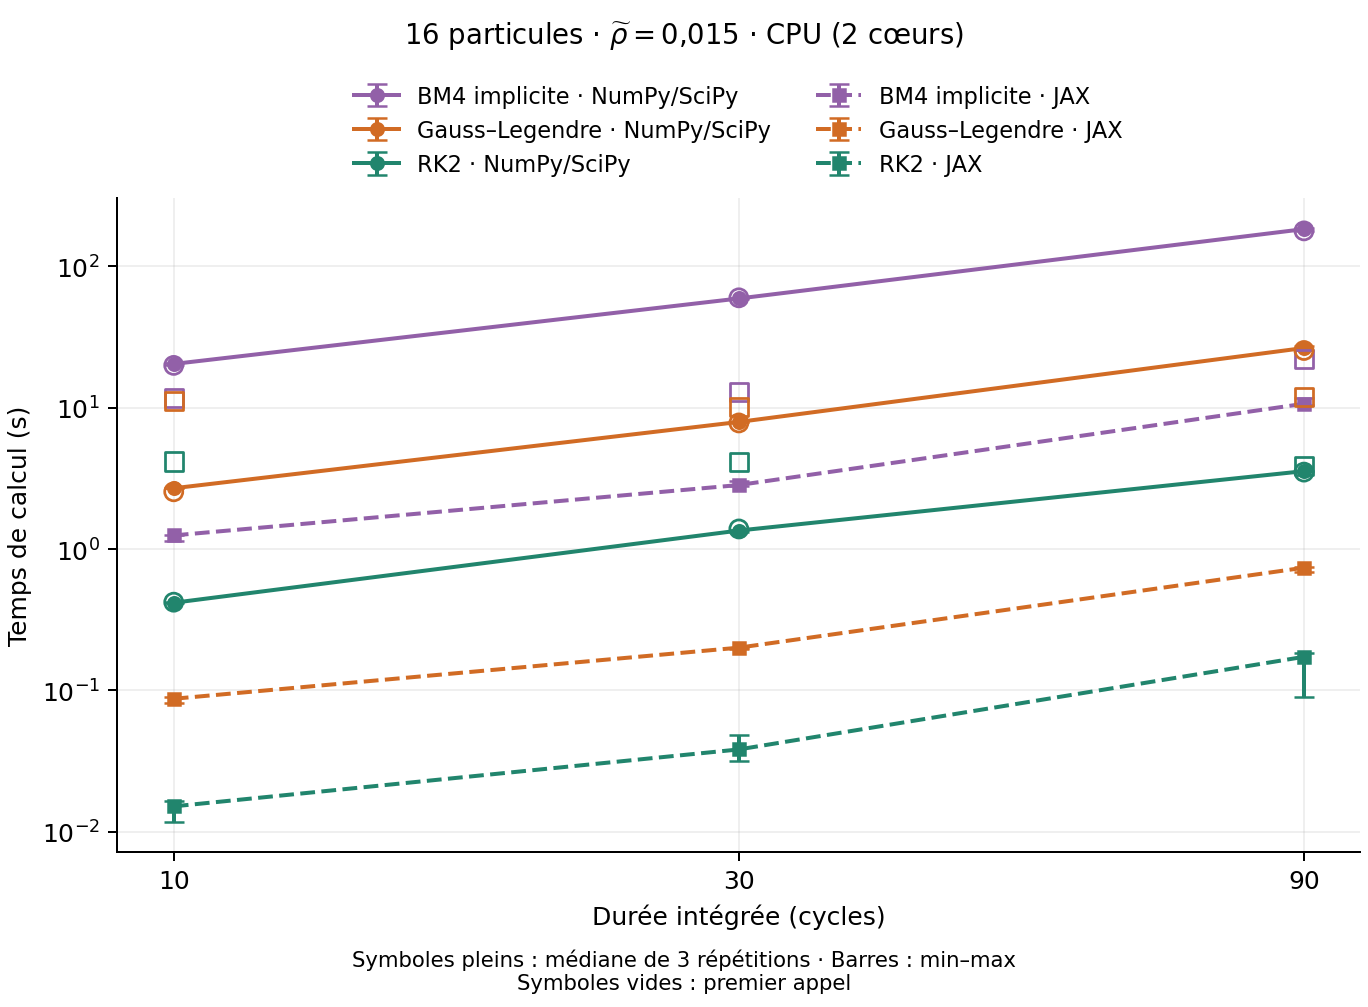

In [4]:
figure = plot_comparison(summary)
plt.show()


Recorded warmed speedup range: 16.3–39.4.
Largest periodic-candidate discrepancy: 5.347e-13 base-cell units.
Chaotic-candidate maxima at 90 cycles:
BM4Implicit 1.837e-06
GaussLegendre4 1.025e-06
RK2 7.554e-07
Backend agreement does not establish integration accuracy or verify the particle classifications.


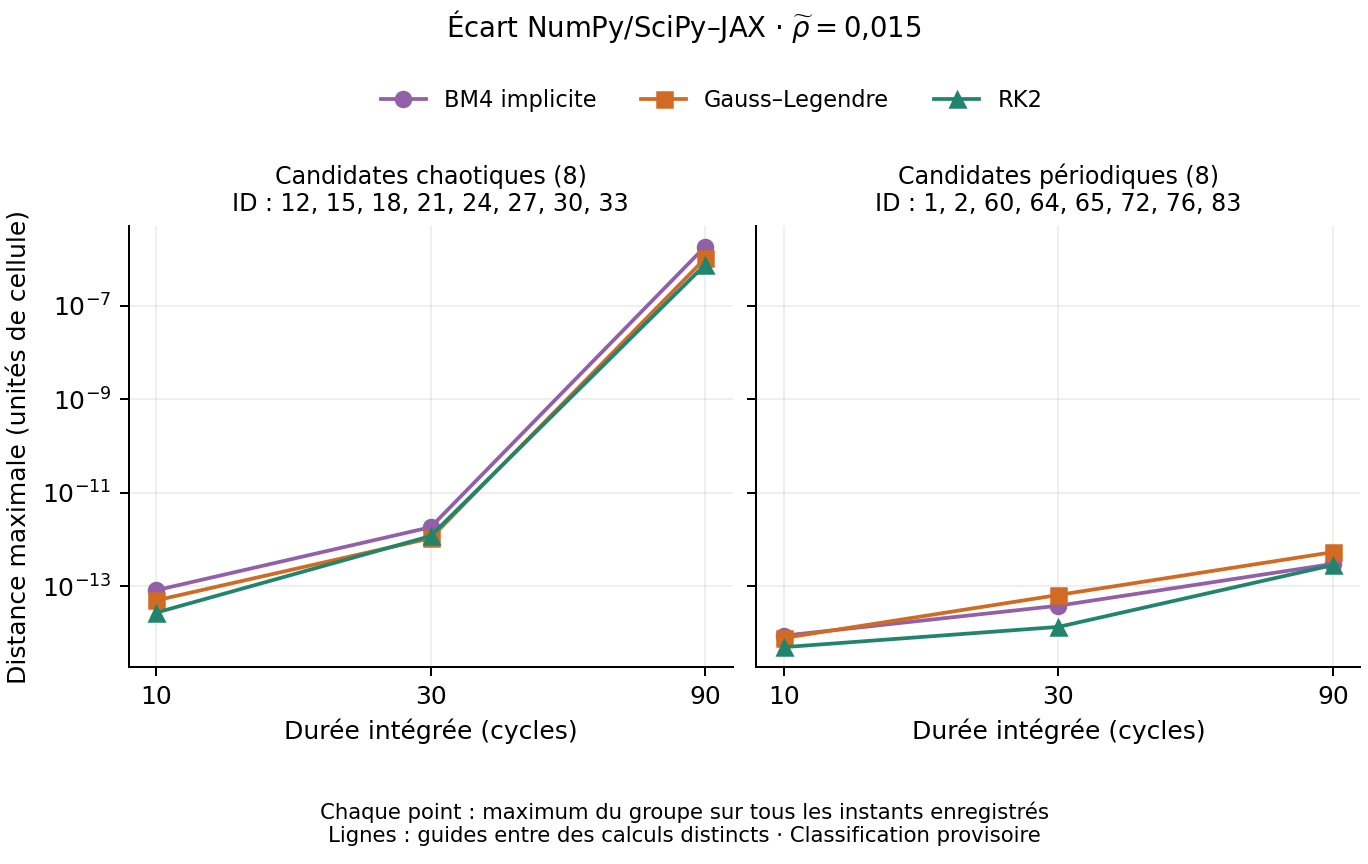

In [5]:
agreement_figure = plot_agreement(summary)
plt.show()
speedups = [row['speedup'] for row in summary['rows']]
periodic_max = max(row['group_distances']['periodic']['maximum_distance'] for row in summary['rows'])
print(f"Recorded warmed speedup range: {min(speedups):.1f}–{max(speedups):.1f}.")
print(f"Largest periodic-candidate discrepancy: {periodic_max:.3e} base-cell units.")
print("Chaotic-candidate maxima at 90 cycles:")
for row in summary['rows']:
    if row['cycles'] == 90:
        print(row['method'], f"{row['group_distances']['chaotic']['maximum_distance']:.3e}")
print("Backend agreement does not establish integration accuracy or verify the particle classifications.")


## Optional local export

Change `EXPORT_FIGURES` to `True` to save PDF, PNG and a JSON record in the
current runtime. In Colab, download them from the Files panel before the runtime
expires. Export writes no thesis repository and uploads nothing. The compact
thesis layout uses the same measurements; these larger panels support reading
on screen. The paired calculation notebook produces new runs separately.


In [6]:
EXPORT_FIGURES = False
EXPORT_DIRECTORY = Path("gc2d-4.3-figures")
if EXPORT_FIGURES:
    EXPORT_DIRECTORY.mkdir(parents=True, exist_ok=True)
    hashes = {}
    for name, item in (("comparacion_numpy_jax_fr", figure), ("concordancia_numpy_jax_fr", agreement_figure)):
        for suffix in (".pdf", ".png"):
            destination = EXPORT_DIRECTORY / (name + suffix)
            metadata = {"CreationDate": None, "ModDate": None} if suffix == ".pdf" else None
            item.savefig(destination, dpi=220, metadata=metadata)
            hashes[destination.name] = sha256(destination.read_bytes()).hexdigest()
    record = dict(summary=summary, public_data_base_url=PUBLIC_DATA_BASE_URL,
        public_manifest_sha256=EXPECTED_MANIFEST_SHA256, figure_sha256=hashes,
        original_archives=public_manifest["source_archives"], new_integrations=False)
    (EXPORT_DIRECTORY / "provenance.json").write_text(json.dumps(record, indent=2, allow_nan=False) + "\n")
    print("Exported figures and provenance to", EXPORT_DIRECTORY.resolve())
else:
    print("Local export disabled; the verified figures are displayed above.")


Local export disabled; the verified figures are displayed above.
